# 2. Install dependencies
# =========================

In [ ]:
!pip install python-dotenv scikit-learn

# 3. Load environment variables from .env
# =========================

In [ ]:
import os
from dotenv import load_dotenv
import tensorflow as tf


In [ ]:
load_dotenv("/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/environment.env")

True

In [ ]:
# Check variables

print("EPOCH", os.getenv("EPOCH"))
print("Classes:", os.getenv("CLASS_NUMBER"))
print("Batch size:", os.getenv("BATCH_SIZE"))
print("Source path:", os.getenv("S_DSET_PATH"))
print("alpha:", os.getenv("alpha"))
print("eta:", os.getenv("eta"))
print("grl_lambda:", os.getenv("grl_lambda"))

EPOCH 50
Classes: 7
Batch size: 16
Source path: /content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged
alpha: 0.5
eta: 0.3
grl_lambda: None


# 4. Import training script
# =========================


In [ ]:
%cd "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation"

/content/drive/MyDrive/Colab Notebooks/Domain Adaptation


In [ ]:
from train_dual_Keras_Model2 import train_mobilenet

# 5. Run training
# =========================

In [ ]:
from train_dual_Keras_Model2 import train_mobilenet, make_datasets, evaluate_model, make_backbone_with_feats, make_domain_discriminator, NoiseCoAdapt, CoDAModel

# Run training
tf.config.run_functions_eagerly(True)
history, model, test_ds, class_names = train_mobilenet()


Found 25079 files belonging to 7 classes.


/usr/local/lib/python3.12/dist-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


Found 2059 files belonging to 7 classes.
Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'co_da_model', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


 99/129 ━━━━━━━━━━━━━━━━━━━━ 2:55 6s/step - accuracy: 0.4594 - adv_loss: 1.3413 - clf_loss: 0.8951 - disc_loss: 0.1201 - f1: 0.2163 - loss: 1.5827 - mmd_loss: 0.0247 - noise_loss: 1.3199Mean class prob (source): [0.0552523024 0.163635045 0.126424462 ... 0.139120847 0.463843137 0.0323772691]
Mean class prob (target): [0.0460805446 0.137874275 0.142751306 ... 0.119719148 0.492257297 0.0410029143]
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.4848 - adv_loss: 1.4705 - clf_loss: 0.8578 - disc_loss: 0.1201 - f1: 0.2297 - loss: 1.4353 - mmd_loss: 0.0251 - noise_loss: 1.2743
Epoch 1: val_f1 improved from -inf to 0.09035, saving model to Model_TF2/20250929_105428/best_coda_model.weights.h5
129/129 ━━━━━━━━━━━━━━━━━━━━ 1688s 13s/step - accuracy: 0.4854 - adv_loss: 1.4716 - clf_loss: 0.8569 - disc_loss: 0.1200 - f1: 0.2301 - loss: 1.4324 - mmd_loss: 0.0252 - noise_loss: 1.2728 - val_accuracy: 0.1719 - val_f1: 0.0904 - val_f12: 0.1076 - val_loss: 1.8524 - val_precision: 0.1545 - val_recal

In [ ]:
# Build model again (with same structure as inside train_mobilenet)
num_classes = int(os.environ.get("CLASS_NUMBER", 7))
net1, feat_extractor1 = make_backbone_with_feats(num_classes)
net2, feat_extractor2 = make_backbone_with_feats(num_classes)
disc = make_domain_discriminator(input_shape=(feat_extractor1.output_shape[-1],))
noise_layer = NoiseCoAdapt(num_classes=num_classes, hidden_dim=128)

model = CoDAModel(net1, net2, feat_extractor1, feat_extractor2,
                  discriminator=disc, noise_layer=noise_layer,
                  alpha=float(os.environ.get("alpha", 0.5)),
                  eta=float(os.environ.get("eta", 0.3)),
                  num_classes=num_classes)

# load weights if needed
# model.load_weights("path/to/final_coda_model.weights.h5")

In [ ]:
# now evaluate+
source_dir = os.getenv("S_DSET_PATH")
target_dir = os.getenv("T_DSET_PATH")
test_dir   = os.getenv("TEST_DSET_PATH")
batch_size = int(os.getenv("BATCH_SIZE", "8"))

_, test_ds, class_names = make_datasets(source_dir, target_dir, test_dir, batch_size)
evaluate_model(model, test_ds, class_names)

Found 25079 files belonging to 7 classes.
Found 2059 files belonging to 7 classes.
              precision    recall  f1-score   support

          ak       0.26      0.07      0.12       175
         bcc       0.46      0.19      0.27       500
         bkl       0.06      0.38      0.11        69
          df       0.25      0.04      0.07        79
         mel       0.33      0.29      0.31       500
          nv       0.18      0.68      0.29       236
         scc       0.49      0.05      0.09       500

    accuracy                           0.23      2059
   macro avg       0.29      0.24      0.18      2059
weighted avg       0.36      0.23      0.21      2059



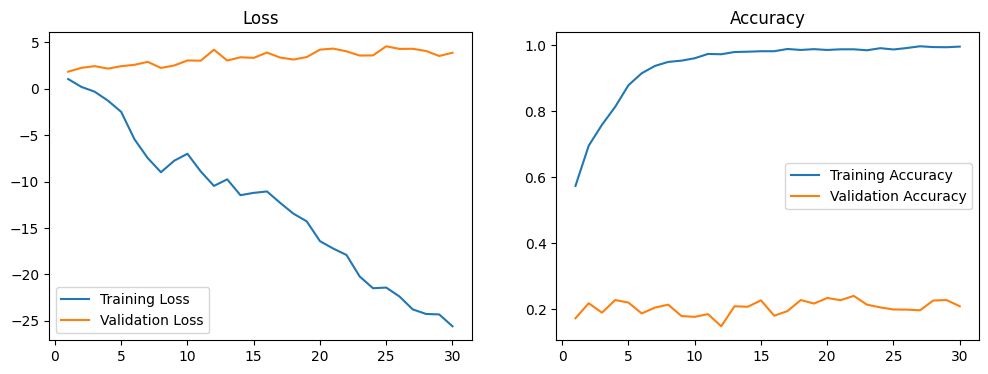

In [ ]:
import matplotlib.pyplot as plt

def plot_history(history):
    hist = history.history
    epochs = range(1, len(hist['loss']) + 1)

    plt.figure(figsize=(12,4))

    # Loss
    plt.subplot(1,2,1)
    plt.plot(epochs, hist['loss'], label='Training Loss')
    if 'val_loss' in hist:
        plt.plot(epochs, hist['val_loss'], label='Validation Loss')
    plt.legend()
    plt.title("Loss")

    # Accuracy
    plt.subplot(1,2,2)
    plt.plot(epochs, hist['accuracy'], label='Training Accuracy')
    if 'val_accuracy' in hist:
        plt.plot(epochs, hist['val_accuracy'], label='Validation Accuracy')
    plt.legend()
    plt.title("Accuracy")

    plt.show()

plot_history(history)

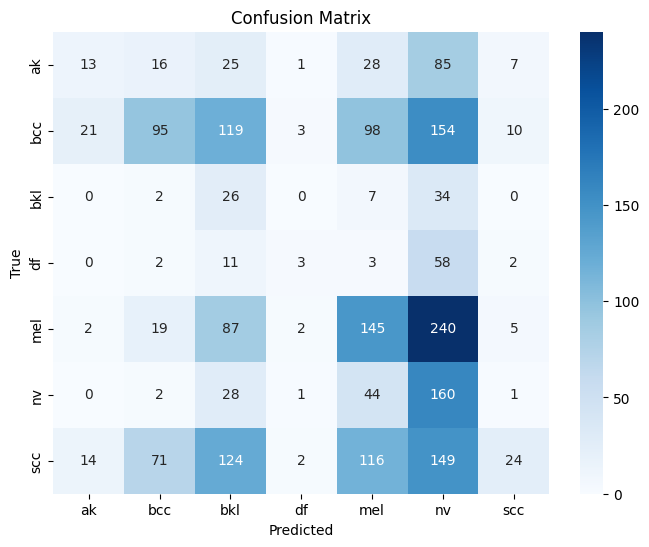

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Collect predictions
y_true, y_pred = [], []
for batch_x, batch_y in test_ds:
    logits1 = model.net1(batch_x, training=False)
    logits2 = model.net2(batch_x, training=False)
    avg_logits = (logits1 + logits2) / 2.0
    preds = tf.argmax(avg_logits, axis=1).numpy()
    labels = tf.argmax(batch_y, axis=1).numpy()
    y_pred.extend(preds)
    y_true.extend(labels)

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def show_samples_per_class(model, test_ds, class_names, samples_per_class=3):
    classifier = model.net1  # or model.net2

    test_images = []
    test_labels = []

    # collect N samples per class
    for class_idx, class_name in enumerate(class_names):
        count = 0
        for img, label in test_ds.unbatch():
            if np.argmax(label.numpy()) == class_idx:
                test_images.append(img.numpy())
                test_labels.append(label.numpy())
                count += 1
                if count >= samples_per_class:
                    break  # stop after enough samples for this class

    test_images = np.array(test_images)
    test_labels = np.array(test_labels)

    preds = classifier.predict(test_images)

    # plot grid
    rows = len(class_names)
    cols = samples_per_class
    plt.figure(figsize=(cols * 3, rows * 3))

    for i in range(len(test_images)):
        ax = plt.subplot(rows, cols, i + 1)

        # show image (already [0,1] floats)
        plt.imshow(np.clip(test_images[i], 0, 1))

        true_label = class_names[np.argmax(test_labels[i])]
        pred_label = class_names[np.argmax(preds[i])]

        color = "green" if true_label == pred_label else "red"
        plt.title(f"T:{true_label}\nP:{pred_label}", color=color, fontsize=9)
        plt.axis("off")

    plt.tight_layout()
    plt.show()


/usr/local/lib/python3.12/dist-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 242ms/step


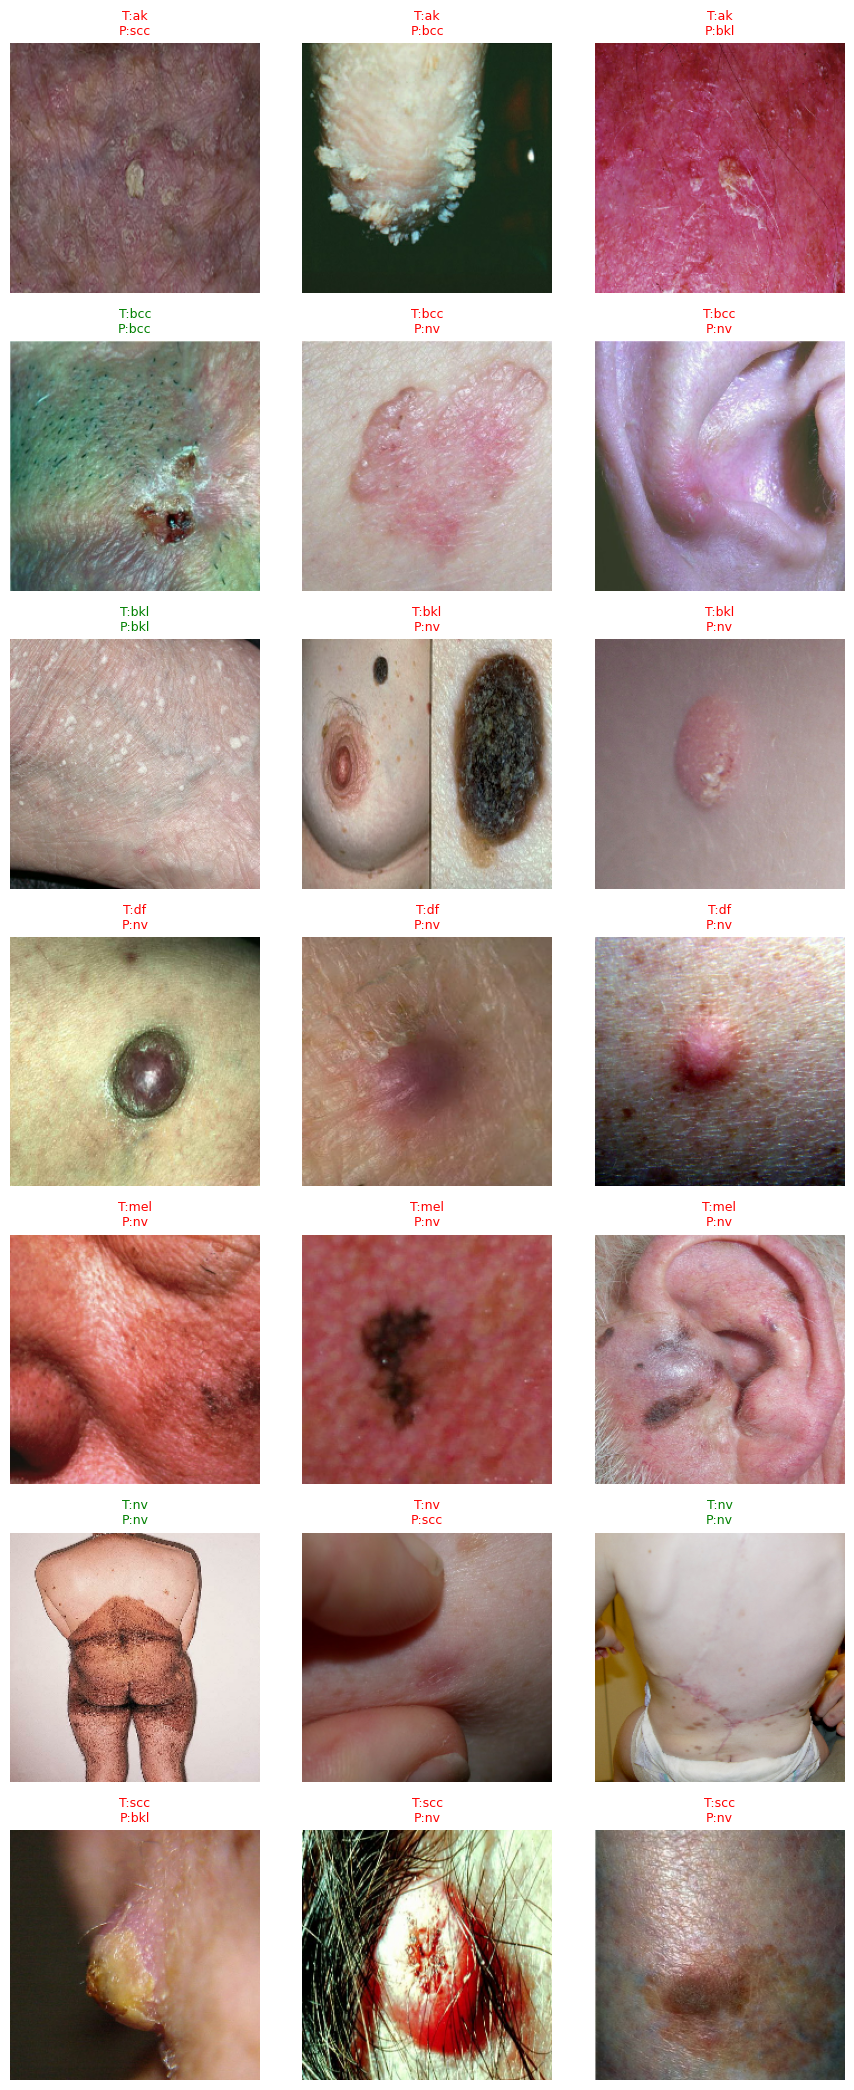

In [ ]:
# Show 3 samples per class
show_samples_per_class(model, test_ds, class_names, samples_per_class=3)


#Load Saved model

In [ ]:
import tensorflow as tf
from train_dual_Keras_Model import make_backbone_with_feats, make_domain_discriminator, NoiseCoAdapt, GradientReversal

# Load the full saved model
model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/Model_TF2/20250929_105428/full_coda_model.keras",
    custom_objects={"CoDAModel": CoDAModel, "NoiseCoAdapt": NoiseCoAdapt, "GradientReversal": GradientReversal}
)

# Load test dataset again
from train_dual_Keras_Model import make_datasets, evaluate_model
import os

source_dir = os.getenv("S_DSET_PATH")
target_dir = os.getenv("T_DSET_PATH")
test_dir   = os.getenv("TEST_DSET_PATH")
batch_size = int(os.getenv("BATCH_SIZE", "8"))

_, test_ds, class_names = make_datasets(source_dir, target_dir, test_dir, batch_size)

# Evaluate the loaded model
evaluate_model(model, test_ds, class_names)


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'adam', because it has 654 variables whereas the saved optimizer has 662 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Found 25079 files belonging to 7 classes.


/usr/local/lib/python3.12/dist-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


Found 2059 files belonging to 7 classes.
              precision    recall  f1-score   support

          ak       0.26      0.07      0.12       175
         bcc       0.46      0.19      0.27       500
         bkl       0.06      0.38      0.11        69
          df       0.25      0.04      0.07        79
         mel       0.33      0.29      0.31       500
          nv       0.18      0.68      0.29       236
         scc       0.49      0.05      0.09       500

    accuracy                           0.23      2059
   macro avg       0.29      0.24      0.18      2059
weighted avg       0.36      0.23      0.21      2059



In [ ]:
from train_dual_Keras_Model2 import (
    CoDAModel, make_backbone_with_feats, make_domain_discriminator,
    NoiseCoAdapt, evaluate_model
)

num_classes = 7
alpha = 0.5
eta = 0.3
grl_lambda = 1.0

# 1️⃣ Rebuild the same structure
net1, feat1 = make_backbone_with_feats(num_classes)
net2, feat2 = make_backbone_with_feats(num_classes)
disc = make_domain_discriminator(input_shape=(feat1.output_shape[-1],))
noise_layer = NoiseCoAdapt(num_classes=num_classes, hidden_dim=128)

# 2️⃣ Initialize and compile model
model = CoDAModel(net1, net2, feat1, feat2,
                  discriminator=disc, noise_layer=noise_layer,
                  alpha=alpha, eta=eta,
                  num_classes=num_classes,
                  grl_lambda=grl_lambda)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4))

# 3️⃣ Build model with dummy input
dummy_source_x = tf.zeros((1, 224, 224, 3))
dummy_source_y = tf.zeros((1, num_classes))
dummy_target_x = tf.zeros((1, 224, 224, 3))
_ = model(((dummy_source_x, dummy_source_y), dummy_target_x), training=False)

# 4️⃣ Load trained weights
model.load_weights("/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/Model_TF2/20250929_105428/best_coda_model.weights.h5")

print("✅ Model and weights loaded successfully!")
print("\n=== net1 last layers ===")
for layer in model.net1.layers[-5:]:
    print(layer.name, "→ has weights:", bool(layer.get_weights()),
          " | mean:", layer.get_weights()[0].mean() if layer.get_weights() else None)

print("\n=== net2 last layers ===")
for layer in model.net2.layers[-5:]:
    print(layer.name, "→ has weights:", bool(layer.get_weights()),
          " | mean:", layer.get_weights()[0].mean() if layer.get_weights() else None)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'co_da_model_2', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


✅ Model and weights loaded successfully!

=== net1 last layers ===
Conv_1 → has weights: True  | mean: 5.38982e-05
Conv_1_bn → has weights: True  | mean: 4.71626
out_relu → has weights: False  | mean: None
global_average_pooling2d_4 → has weights: False  | mean: None
dense_14 → has weights: True  | mean: -0.0027788766

=== net2 last layers ===
Conv_1 → has weights: True  | mean: -3.0501003e-05
Conv_1_bn → has weights: True  | mean: 4.7162905
out_relu → has weights: False  | mean: None
global_average_pooling2d_5 → has weights: False  | mean: None
dense_15 → has weights: True  | mean: -0.0018724722


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 662 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
for w in model.net1.layers[:5]:
    print(w.name, w.get_weights()[0].mean() if w.get_weights() else "no weights")


input_layer_6 no weights
Conv1 -0.0050924635
bn_Conv1 1.1676695
Conv1_relu no weights
expanded_conv_depthwise -0.061078046


In [ ]:
import tensorflow as tf

for x, y in test_ds.take(1):
    logits1 = model.net1(x)
    logits2 = model.net2(x)
    avg_logits = (logits1 + logits2) / 2.0
    pred = tf.argmax(avg_logits, axis=1)
    print("Predicted:", pred.numpy(), "True:", tf.argmax(y, axis=1).numpy())


Predicted: [0] True: [0]


In [ ]:
# 5️⃣ Evaluate
evaluate_model(model, test_ds, class_names)

              precision    recall  f1-score   support

          ak       0.26      0.07      0.12       175
         bcc       0.46      0.19      0.27       500
         bkl       0.06      0.38      0.11        69
          df       0.25      0.04      0.07        79
         mel       0.33      0.29      0.31       500
          nv       0.18      0.68      0.29       236
         scc       0.49      0.05      0.09       500

    accuracy                           0.23      2059
   macro avg       0.29      0.24      0.18      2059
weighted avg       0.36      0.23      0.21      2059



In [ ]:
import tensorflow as tf

# Image size and rescaling (must match training)
img_size = (224, 224)
rescale = tf.keras.layers.Rescaling(1./255)

# Create test dataset
test_loader = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="categorical",
    batch_size=1,
    image_size=img_size,
    shuffle=False
)

# Apply same normalization as training
test_ds = test_loader.map(
    lambda x, y: (rescale(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

# Capture class names for reporting
class_names = test_loader.class_names

print("✅ Test dataset rebuilt successfully with", len(class_names), "classes:", class_names)


Found 2059 files belonging to 7 classes.
✅ Test dataset rebuilt successfully with 7 classes: ['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']


In [ ]:
import numpy as np

all_preds = []
for batch_x, _ in test_ds.take(100):
    logits1 = model.net1(batch_x, training=False)
    logits2 = model.net2(batch_x, training=False)
    avg_logits = (logits1 + logits2) / 2.0
    preds = tf.argmax(avg_logits, axis=1).numpy()
    all_preds.extend(preds)

unique, counts = np.unique(all_preds, return_counts=True)
print("Prediction distribution on 100 test samples:", dict(zip(unique, counts)))


Prediction distribution on 100 test samples: {np.int64(5): np.int64(100)}
